# 16.100 Project 2 — starter notebook

In this notebook you write seven short functions for Tasks 1 to 5 of the handout. Each one raises `NotImplementedError` until you write it. Below each function is a self-check cell. Then a design panel uses your functions. You move the seven design variables, and the panel shows the planform, the twist, the camber and the wing loading.

**Files in this folder**

| File | What it is | Do you edit it? |
|---|---|---|
| `p2_starter.ipynb` | this notebook | yes: this is your work |
| `p2_inputs.toml` | every number the notebook needs; your P1 values in `[p1]`; the start values of the panel in `[design]` | `[p1]` and `[design]` |
| `p2_lib.py` | code we give you: the wing geometry, the lifting-line solver, the drag function `cd`, the checks and the panel | no |
| `p2_answers.toml` | the answer file you submit | yes: replace every `nan` |
| `validate_p2_answers.py` | checks the format of your answer file | no |

**Running in the browser.** If you opened this at the course's JupyterLite link, everything runs inside your browser. Nothing is installed and nothing is sent to a server. Your edits are saved **in this browser only**. Download your files often (right-click a file in the file browser on the left, then *Download*). Download them before you clear your browser data or change to a different computer.

**Running on your own computer.** Download the folder and open the notebook with Jupyter. You need Python 3.11 or later with `numpy`, `matplotlib` and `ipywidgets`.

**What to upload to Canvas:** your report PDF, this notebook (and any other notebooks or scripts you used), and your filled-in `p2_answers.toml`.

## 0. Set up

First, put your team's P1 values in the `[p1]` section of `p2_inputs.toml` and save the file. (Open it from the file browser on the left.) The file has the staff P1 design as an example.

Run the cell below. In the browser, it first installs `ipywidgets`, the package for the sliders. This can take some seconds.

In [20]:
import sys
if sys.platform == "emscripten":          # in the browser (JupyterLite): install the slider package
    import piplite
    await piplite.install("ipywidgets")

import numpy as np
import matplotlib.pyplot as plt
from p2_lib import *

inp = load_inputs("p2_inputs.toml")
print(f"W = {inp.W_N} N, S = {inp.S_m2} m^2, b = {inp.b_m} m, AR = {inp.b_m**2 / inp.S_m2:.2f}")
print(f"cruise: V = {inp.V_cruise} m/s, q = {inp.q_cruise:.1f} Pa, C_L = {inp.CL_cruise:.3f}")
print(f"required wing C_Lmax = {inp.CLmax_req}")
if uses_staff_example(inp):
    print("\nNOTE: these are the STAFF example P1 values. Put your team's values in [p1] of "
          "p2_inputs.toml, save the file, and run this cell again.")

W = 19.78 N, S = 0.633 m^2, b = 1.59 m, AR = 3.99
cruise: V = 8.35 m/s, q = 42.7 Pa, C_L = 0.732
required wing C_Lmax = 1.04


## 1. The tools you are given

**The wing.** `make_design(inp, ...)` makes a two-panel wing with your $S$ and $b$. Its seven design variables have the same names everywhere (in `p2_inputs.toml`, in a design, and in `p2_answers.toml`):

| Name | Handout | Unit |
|---|---|---|
| `cb_cr`, `ct_cr` | $c_b/c_r$, $c_t/c_r$ | — |
| `theta_b_deg`, `theta_t_deg` | $\theta_b$, $\theta_t$ | deg, relative to the root chord, nose up positive |
| `m_r_pct`, `m_b_pct`, `m_t_pct` | $m_r$, $m_b$, $m_t$ | % of the chord, at the root, the break and the tip |

A design `d` gives `d.c_r` (m), `d.S`, `d.b`, `d.AR`, and these functions of $\eta = 2y/b$: `d.chord(eta)` in m, `d.twist(eta)` in rad, `d.twist_deg(eta)` in deg, and `d.camber(eta)` in %.

**Span stations.** `ETA` is an array of 400 stations on the half wing, $0 < \eta < 1$. Your functions return their results at these stations. `span_integral(f)` gives $\int_0^1 f\,d\eta$ for an array `f` of values at `ETA`. There is no station exactly at the root, at the tip or at the break.

**The lifting line.** `lifting_line(b, chord, twist, alpha_L0, alpha=..., S=...)` solves Eq. (3) of the handout. `chord` (m), `twist` (rad) and `alpha_L0` (rad) are functions of $\eta$, or one number for every station. `alpha` is the angle of attack of the root chord, in rad. You can give `CL=...` instead of `alpha`. `S` is the wing area in m$^2$; if you leave it out, the solver finds it from the chord. The result `ll` has `ll.CL`, `ll.CDi`, `ll.e`, the coefficients `ll.A`, and the function `ll.cl(eta)`, the section lift coefficient $c_l$.

The cell below uses these tools. It needs no code from you.

In [21]:
d = make_design(inp, ct_cr=0.5, theta_t_deg=-2.0)     # the [design] values, with a smaller tip chord and washout
print(f"c_r = {d.c_r:.4f} m, AR = {d.AR:.2f}")
for eta in (0.0, 0.25, 0.5, 0.75, 1.0):
    print(f"eta = {eta:4.2f}: chord = {d.chord(eta):.4f} m, twist = {d.twist_deg(eta):5.2f} deg, camber = {d.camber(eta):.2f} %")

# lifting line for this wing, with alpha_L0 = 0 at every station (a symmetric section)
ll = lifting_line(d.b, d.chord, d.twist, 0.0, alpha=np.radians(5.0))
print(f"\nalpha = 5 deg: C_L = {ll.CL:.4f}, C_Di = {ll.CDi:.5f}, e = {ll.e:.4f}")
print(f"c_l at eta = 0, 0.5, 0.9: {np.round(ll.cl(np.array([0.0, 0.5, 0.9])), 4)}")

c_r = 0.4550 m, AR = 3.99
eta = 0.00: chord = 0.4550 m, twist =  0.00 deg, camber = 4.00 %
eta = 0.25: chord = 0.4550 m, twist =  0.00 deg, camber = 4.00 %
eta = 0.50: chord = 0.4550 m, twist =  0.00 deg, camber = 4.00 %
eta = 0.75: chord = 0.3412 m, twist = -1.00 deg, camber = 4.00 %
eta = 1.00: chord = 0.2275 m, twist = -2.00 deg, camber = 4.00 %

alpha = 5 deg: C_L = 0.3376, C_Di = 0.00913, e = 0.9951
c_l at eta = 0, 0.5, 0.9: [0.3809 0.3348 0.2508]


## 2. Task 1: sections

All sections are NACA $m$412. `naca4_camber(x, m, p)` gives the camber line $z/c$ and its slope $dz/dx$ at the chord stations `x` ($x/c$, from 0 to 1). Here `m` and `p` are fractions of the chord: `m = 0.04, p = 0.4` is a NACA 4412.

Write `section_properties(m, p)`. It returns the zero-lift angle $\alpha_{L0}$ (rad) and the moment coefficient $c_{m,c/4}$, from handout Eq. (1):

$$\alpha_{L0}=-\frac1\pi\int_0^\pi\frac{dz}{dx}\,(\cos\vartheta-1)\,d\vartheta,\qquad
c_{m,c/4}=\frac\pi4\,(A_2-A_1),\qquad A_n=\frac2\pi\int_0^\pi\frac{dz}{dx}\cos n\vartheta\,d\vartheta,$$

with $x/c=\tfrac12(1-\cos\vartheta)$. Do the integrals numerically, for example with `np.trapezoid` on about 2000 values of $\vartheta$ from 0 to $\pi$.

**Given tools for this function** (from `p2_lib.py`, already imported):
- `naca4_camber(x, m, p)` returns `(z, dzdx)`: the camber line $z/c$ and its slope $dz/dx$ at the chord stations `x` ($x/c$).
- `np.trapezoid(y, x)` integrates the values `y` over `x`.

In [22]:
def section_properties(m, p):
    """Thin-airfoil properties of a NACA 4-digit camber line (handout Eq. 1).

    m: maximum camber, as a fraction of the chord (0.04 for a NACA 4412).
    p: position of the maximum camber, as a fraction of the chord (0.4).
    Returns (alpha_L0, cm_c4): the zero-lift angle in radians, and the moment
    coefficient about the quarter chord.

    Tools to use:
      naca4_camber(x, m, p) -> (z, dzdx), the camber line and its slope at x = x/c.
      np.trapezoid(y, theta) for the three integrals over theta from 0 to pi.
    """

    theta = np.linspace(0.0, np.pi, 2000)
    x = 0.5 * (1.0 - np.cos(theta))          # x/c = (1 - cos(theta)) / 2
    _, dzdx = naca4_camber(x, m, p)

    alpha_L0 = -(1.0 / np.pi) * np.trapezoid(dzdx * (np.cos(theta) - 1.0), theta)
    A1 = (2.0 / np.pi) * np.trapezoid(dzdx * np.cos(theta), theta)
    A2 = (2.0 / np.pi) * np.trapezoid(dzdx * np.cos(2.0 * theta), theta)
    cm_c4 = (np.pi / 4.0) * (A2 - A1)

    return alpha_L0, cm_c4

In [4]:
check_section_properties(section_properties)

Checks for section_properties(m, p):
  ok    a symmetric section (m = 0) gives alpha_L0 = 0 and c_m,c/4 = 0
  ok    alpha_L0 is in radians
  ok    positive camber gives a negative alpha_L0 (the section lifts at zero angle)
  ok    positive camber gives a nose-down (negative) c_m,c/4
  ok    alpha_L0 and c_m,c/4 are proportional to m (thin airfoil theory is linear in the camber)
  ok    a NACA 4412 has c_l0 = 0.46, as the handout says
All 6 checks passed. (The checks find common mistakes. They do not prove that your function is correct.)


Next, the stall rule, handout Eq. (2): a section stalls when $c_l \ge c_{l\max} = c_{l0} + 0.99$, where $c_{l0} = -2\pi\alpha_{L0}$ is the zero-angle lift coefficient. Take the constant 0.99 from `inp.dcl_stall`. Your function must work for one number and for a numpy array.

**Given tools for this function** (from `p2_lib.py`, already imported):
- `inp.dcl_stall`: the stall constant, 0.99.

In [23]:
def cl_max(inp, cl0):
    """Section stall limit, handout Eq. (2).

    cl0: zero-angle lift coefficient, -2 pi alpha_L0 (a number or an array).
    Returns c_lmax, with the same shape as cl0.

    Tools to use:
      inp.dcl_stall, the stall constant 0.99.
    """
    return inp.dcl_stall + cl0

In [7]:
check_cl_max(inp, cl_max)

Checks for cl_max(inp, cl0):
  ok    a 0012 stalls at c_l = 0.99 and a 4412 at 1.45
  ok    works on a numpy array of c_l0 values
All 2 checks passed. (The checks find common mistakes. They do not prove that your function is correct.)


The table for Task 1.1. It uses your two functions.

In [6]:
try:
    print("section   alpha_L0 (deg)   c_l0    c_m,c/4   c_lmax")
    for m in (0.0, 0.02, 0.04, 0.06):
        alpha_L0, cm_c4 = section_properties(m, inp.p_camber)
        cl0 = -2 * np.pi * alpha_L0
        name = "NACA 0012" if m == 0 else f"NACA {100 * m:.0f}412"
        print(f"{name}   {np.degrees(alpha_L0):10.3f}   {cl0:8.4f}  {cm_c4:8.4f}  {cl_max(inp, cl0):7.3f}")
except NotImplementedError as err:
    print("Not written yet.", err)

section   alpha_L0 (deg)   c_l0    c_m,c/4   c_lmax
NACA 0012       -0.000     0.0000    0.0000    0.990
NACA 2412       -2.077     0.2278   -0.0531    1.218
NACA 4412       -4.154     0.4556   -0.1062    1.446
NACA 6412       -6.232     0.6834   -0.1594    1.673


## 3. Task 2: how a wing spreads its lift

The wing $c_l$ at each station is a fixed part plus a part proportional to the wing $C_L$ (handout Eq. 4):

$$c_l(\eta) = c_{l,b}(\eta) + C_L\,\frac{\partial c_l}{\partial C_L}(\eta).$$

$c_{l,b}$ is the basic loading: the $c_l$ at each station when the wing $C_L$ is zero. $\partial c_l/\partial C_L$ is the additional loading: the rise of $c_l$ at a station when the wing $C_L$ rises by 1.

Write `loadings(design)`. It returns `(cl_b, dcl_dCL)`, two arrays with the value at each station in `ETA`. Do this:

1. Get $\alpha_{L0}(\eta)$ from your `section_properties`:
   `alpha_L0, cm_c4 = span_sections(design, section_properties)`.
   Both are functions of $\eta$. Thin airfoil theory is linear in the camber line, so they change along the span in the same way as the camber.
2. The lifting-line equation is linear in the angle of attack. Solve it at two different angles of attack, for example
   `lifting_line(design.b, design.chord, design.twist, alpha_L0, alpha=0.0, S=design.S)`.
3. From the two solutions (their $C_L$ and their $c_l$ at `ETA`), find the two parts of Eq. (4).

**Given tools for this function** (from `p2_lib.py`, already imported):
- `span_sections(design, section_properties)` returns `(alpha_L0, cm_c4)`: two functions of $\eta$.
- `lifting_line(b, chord, twist, alpha_L0, alpha=..., S=...)` returns `ll`, with `ll.CL` and `ll.cl(eta)`.
- `design.b`, `design.S`, `design.chord`, `design.twist`: the span (m), the area (m$^2$), and the chord (m) and twist (rad) as functions of $\eta$.
- `ETA`: the 400 span stations.

In [24]:
def loadings(design):
    """Basic and additional loading, handout Eq. (4), at the stations ETA.

    Returns (cl_b, dcl_dCL): two arrays with the value at each station in ETA.
    cl_b is the section c_l when the wing C_L is zero. dcl_dCL is the rise of the
    section c_l per unit rise of the wing C_L.

    Tools to use:
      span_sections(design, section_properties) -> (alpha_L0, cm_c4), functions of eta.
      lifting_line(design.b, design.chord, design.twist, alpha_L0, alpha=..., S=design.S),
        solved at two angles of attack; each result has .CL and .cl(eta).
      ETA, the stations where you return the values.
    """
    alpha_L0, cm_c4 = span_sections(design, section_properties)

    a1, a2 = 0.0, 0.1   # two angles of attack (rad)
    ll1 = lifting_line(design.b, design.chord, design.twist, alpha_L0,
                       alpha=a1, S=design.S)
    ll2 = lifting_line(design.b, design.chord, design.twist, alpha_L0,
                       alpha=a2, S=design.S)

    cl1 = np.asarray(ll1.cl(ETA))
    cl2 = np.asarray(ll2.cl(ETA))

    # Eq. (4): cl(eta) = cl_b(eta) + CL * dcl/dCL(eta)
    dcl_dCL = (cl2 - cl1) / (ll2.CL - ll1.CL)    # slope between the two solutions
    cl_b = cl1 - ll1.CL * dcl_dCL                # value where CL = 0

    return cl_b, dcl_dCL

In [10]:
check_loadings(inp, loadings)

Checks for loadings(design):
  ok    returns two arrays at the stations ETA
  ok    no twist and one section: the basic loading c_l,b is zero
  ok    the span load of the additional loading, c (dc_l/dC_L)/c_avg, has an average of 1
  ok    the basic loading makes no net lift: the average of c c_l,b / c_avg is zero
  ok    with washout, c_l,b is positive at the root and negative near the tip
All 5 checks passed. (The checks find common mistakes. They do not prove that your function is correct.)


**Plots for Task 2 (b) and (c).** The next cell makes the wings of the handout. All of them have your $S$ and $b$, and NACA 4412 everywhere. They do not use the `[design]` values of `p2_inputs.toml`.

- (b) `wings_b`: the tapered wing ($c_b = 0.75\,c_r$, $c_t = 0.5\,c_r$) with $4^\circ$ of washout and with $4^\circ$ of washin. The twist changes linearly from 0 at the root to $\theta_t$ at the tip, so $\theta_b = \theta_t/2$.
- (c) `wings_c`: a rectangular wing, and the same tapered wing with no twist.

For a wing `d`, your `loadings(d)` gives $c_{l,b}$ and $\partial c_l/\partial C_L$ at `ETA`, and `d.chord(ETA)` gives the chord in m. For the span load, divide $c\,c_l$ by $c_\text{avg} = S/b$ (`c_avg`). Make your plots in the cell after it.

In [13]:
# The wings of handout Task 2 (b) and (c): your S and b, NACA 4412 everywhere
naca4412 = dict(m_r_pct=4.0, m_b_pct=4.0, m_t_pct=4.0)
taper = dict(cb_cr=0.75, ct_cr=0.5)
wings_b = {"washout": make_design(inp, **naca4412, **taper, theta_b_deg=-2.0, theta_t_deg=-4.0),
           "washin": make_design(inp, **naca4412, **taper, theta_b_deg=2.0, theta_t_deg=4.0)}
wings_c = {"rectangular": make_design(inp, **naca4412, cb_cr=1.0, ct_cr=1.0, theta_b_deg=0.0, theta_t_deg=0.0),
           "taper": make_design(inp, **naca4412, **taper, theta_b_deg=0.0, theta_t_deg=0.0)}
c_avg = inp.S_m2 / inp.b_m
print(f"c_avg = {c_avg:.4f} m; root chord: rectangular {wings_c['rectangular'].c_r:.4f} m, "
      f"taper {wings_c['taper'].c_r:.4f} m")

print((2*inp.W_N)/((6.04**2)*(inp.rho*inp.S_m2)))

c_avg = 0.2409 m; root chord: rectangular 0.2409 m, taper 0.3212 m
2.3112532934103314


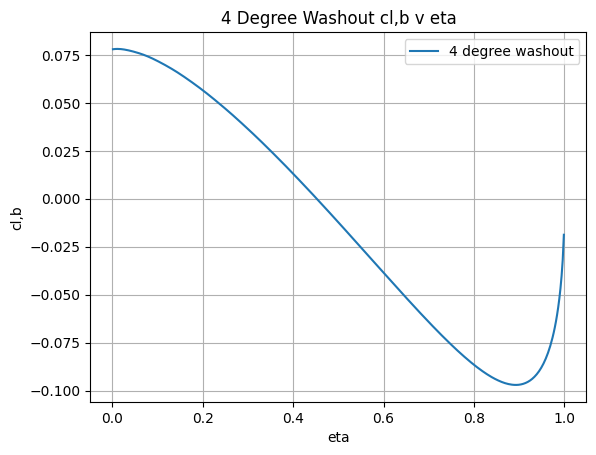

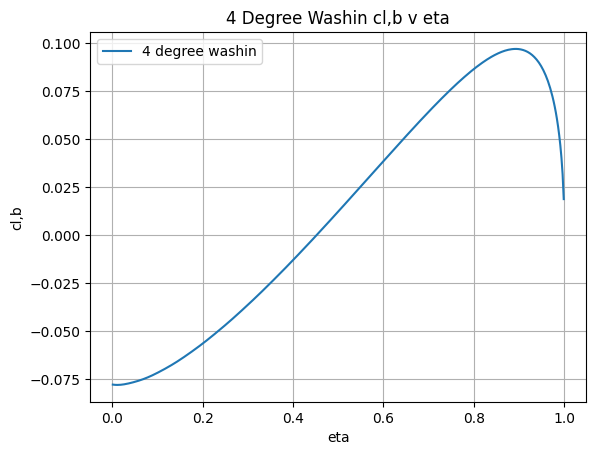

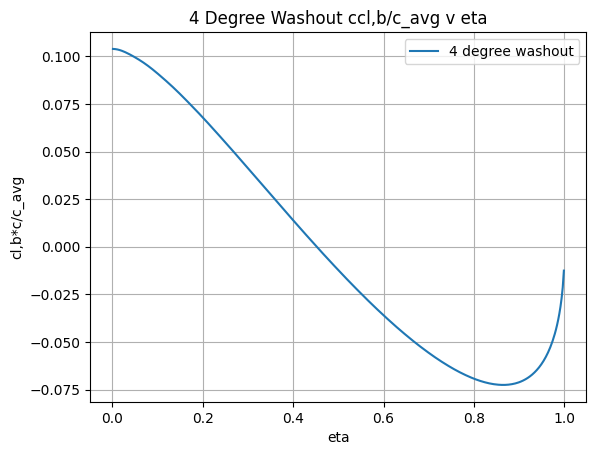

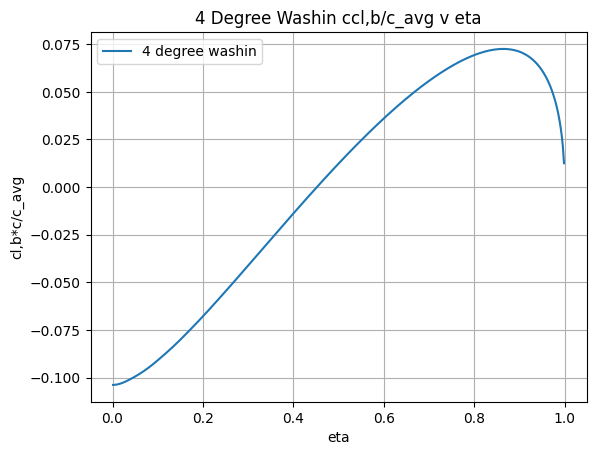

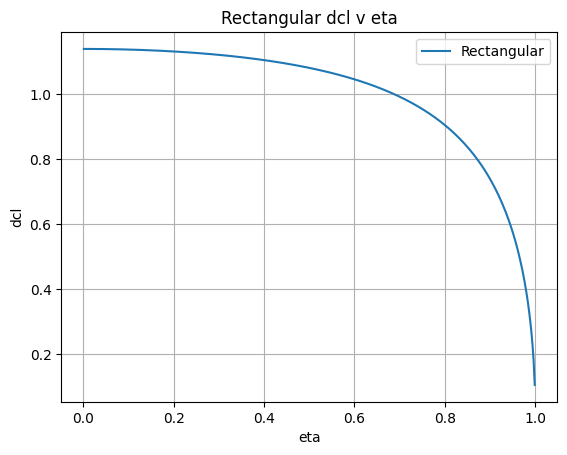

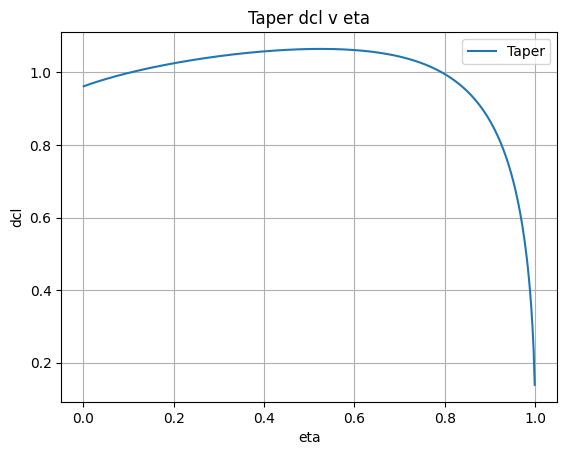

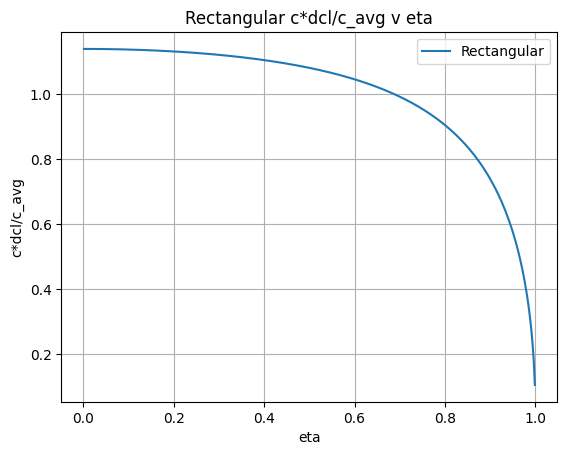

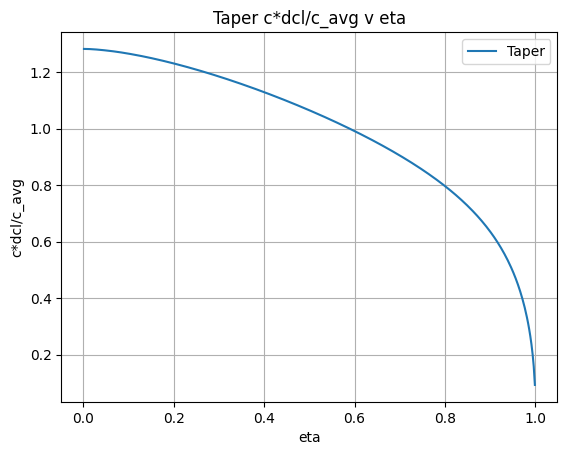

In [12]:
# Task 2 (b) and (c): your plots

#Task 2.b plots
cl_b_washout, _ = loadings(wings_b["washout"])
cl_b_washin, _ =  loadings(wings_b["washin"])

plt.plot(ETA, cl_b_washout, label = "4 degree washout")
plt.title("4 Degree Washout cl,b v eta")
plt.ylabel("cl,b")
plt.xlabel("eta")
plt.grid()
plt.legend()
plt.show()

plt.plot(ETA, cl_b_washin, label = "4 degree washin")
plt.title("4 Degree Washin cl,b v eta")
plt.ylabel("cl,b")
plt.xlabel("eta")
plt.grid()
plt.legend()
plt.show()

c = wings_b["washout"].chord(ETA)
ccl_b_washout = cl_b_washout*c/c_avg
ccl_b_washin = cl_b_washin*wings_b["washin"].chord(ETA)/c_avg


plt.plot(ETA, ccl_b_washout, label = "4 degree washout")
plt.title("4 Degree Washout ccl,b/c_avg v eta")
plt.ylabel("cl,b*c/c_avg")
plt.xlabel("eta")
plt.grid()
plt.legend()
plt.show()

plt.plot(ETA, ccl_b_washin, label = "4 degree washin")
plt.title("4 Degree Washin ccl,b/c_avg v eta")
plt.ylabel("cl,b*c/c_avg")
plt.xlabel("eta")
plt.grid()
plt.legend()
plt.show()

#Task 2.c plots

_, dcl_rect = loadings(wings_c["rectangular"])
_, dcl_tap = loadings(wings_c["taper"])

plt.plot(ETA, dcl_rect, label = "Rectangular")
plt.title("Rectangular dcl v eta")
plt.ylabel("dcl")
plt.xlabel("eta")
plt.grid()
plt.legend()
plt.show()

plt.plot(ETA, dcl_tap, label = "Taper")
plt.title("Taper dcl v eta")
plt.ylabel("dcl")
plt.xlabel("eta")
plt.grid()
plt.legend()
plt.show()

cdcl_rect = dcl_rect*wings_c["rectangular"].chord(ETA)/c_avg
cdcl_tap = dcl_tap*wings_c["taper"].chord(ETA)/c_avg

plt.plot(ETA, cdcl_rect, label = "Rectangular")
plt.title("Rectangular c*dcl/c_avg v eta")
plt.ylabel("c*dcl/c_avg")
plt.xlabel("eta")
plt.grid()
plt.legend()
plt.show()

plt.plot(ETA, cdcl_tap, label = "Taper")
plt.title("Taper c*dcl/c_avg v eta")
plt.ylabel("c*dcl/c_avg")
plt.xlabel("eta")
plt.grid()
plt.legend()
plt.show()

**The stall front.** Set Eq. (4) equal to $c_{l\max}(\eta)$ and solve for the wing $C_L$ (handout Eq. 5):

$$C_L^*(\eta)=\frac{c_{l\max}(\eta)-c_{l,b}(\eta)}{\partial c_l/\partial C_L\,(\eta)} .$$

$C_L^*(\eta)$ is the wing $C_L$ at which station $\eta$ stalls. The wing $C_{L\max}$ is the lowest $C_L^*$ for $\eta \le 0.9$ (`inp.eta_check`). The station of that lowest value is where the stall starts.

Write `stall_front(inp, design)`. It returns `(CL_star, CLmax, eta_first)`:

- `CL_star`: $C_L^*$ at every station in `ETA` (an array);
- `CLmax`: the wing $C_{L\max}$ (a number);
- `eta_first`: the station $\eta$ where the stall starts (a number).

Use only the stations with `ETA <= inp.eta_check` to find `CLmax` and `eta_first`.

Your function can call your other functions: `loadings(design)` gives $c_{l,b}$ and $\partial c_l/\partial C_L$. `span_sections` gives $\alpha_{L0}(\eta)$, so $c_{l0}$ and then `cl_max(inp, cl0)` give $c_{l\max}(\eta)$.

**Given tools for this function** (from `p2_lib.py`, already imported):
- `loadings(design)` (yours): `(cl_b, dcl_dCL)` at `ETA`.
- `span_sections(design, section_properties)`: `alpha_L0(eta)`, so `cl0 = -2 * np.pi * alpha_L0(ETA)`.
- `cl_max(inp, cl0)` (yours): $c_{l\max}$ at each station.
- `ETA` and `inp.eta_check` (0.9): use `ETA <= inp.eta_check` to pick the stations that count.

CLmax equals 1.2703565934473395 Stall start equals 0.00125


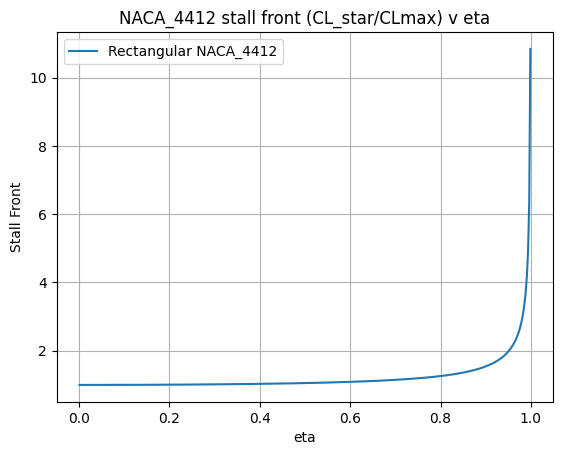

In [17]:
def stall_front(inp, design):
    """Stall front, handout Eq. (5).

    Returns (CL_star, CLmax, eta_first):
      CL_star   the wing C_L at which each station in ETA stalls (an array),
      CLmax     the lowest CL_star for eta <= inp.eta_check (a number),
      eta_first the station eta of that lowest value: where the stall starts.

    Tools to use:
      loadings(design) (yours) -> (cl_b, dcl_dCL) at ETA.
      span_sections(design, section_properties) -> alpha_L0(eta); cl0 = -2 pi alpha_L0(ETA).
      cl_max(inp, cl0) (yours) -> c_lmax at each station.
      ETA <= inp.eta_check picks the stations that count for CLmax and eta_first.
    """
    cl_b, dcl_dCL = loadings(design)
    alpha_L0, _ = span_sections(design, section_properties)
    cl0 = -2.0 * np.pi * np.asarray(alpha_L0(ETA))
    clmax = cl_max(inp, cl0)

    # Eq. (5): set cl_b + CL * dcl_dCL = clmax and solve for the wing CL
    CL_star = (clmax - cl_b) / dcl_dCL

    # Only stations inboard of eta_check count for CLmax and the stall start
    mask = ETA <= inp.eta_check
    idx = np.argmin(np.where(mask, CL_star, np.inf))

    CLmax = CL_star[idx]
    eta_first = ETA[idx]

    return CL_star, CLmax, eta_first

n4412 = wings_c["rectangular"] #wings_c rectangular model is the same as specificied for this part
CL_star, CLmax, eta_first = stall_front(inp, n4412)

print("CLmax equals", CLmax, "Stall start equals", eta_first)

plt.plot(ETA, CL_star/ CLmax, label = "Rectangular NACA_4412")
plt.title("NACA_4412 stall front (CL_star/CLmax) v eta")
plt.ylabel("Stall Front")
plt.xlabel("eta")
plt.grid()
plt.legend()
plt.show()


In [14]:
check_stall_front(inp, stall_front, section_properties)

Checks for stall_front(inp, design):
  ok    CL_star is an array at the stations ETA
  ok    CLmax is the lowest C_L* for eta <= 0.9
  ok    the first stall is at eta <= 0.9 (the rule is not applied outboard)
  ok    rectangular NACA 4412 wing: 0.9 < CLmax < 1.45
  ok    rectangular, untwisted wings: CLmax scales with c_l,max (NACA 4412 against 0012)
All 5 checks passed. (The checks find common mistakes. They do not prove that your function is correct.)


## 4. Task 3: profile drag

The wing profile drag coefficient is

$$C_{D_p}=\frac1S\int_{-b/2}^{b/2}c_d\,c\,dy .$$

`cd(inp, m, cl, cl0, Re)` gives the section drag coefficient $c_d$ of a NACA $m$412 section. All four inputs can be arrays:

- `m`: the camber, in %;
- `cl`: the section $c_l$;
- `cl0`: the zero-angle lift coefficient of the section, $c_{l0} = -2\pi\alpha_{L0}$;
- `Re`: the Reynolds number of the local chord, $Vc/\nu$.

Write `profile_drag(inp, design, CL, V)`. It returns $C_{D_p}$ at the wing lift coefficient `CL` and the flight speed `V` (m/s). At the stations `ETA`:

- the section $c_l$ comes from your `loadings` and Eq. (4);
- the camber is `design.camber(ETA)` (in %), and the chord is `c = design.chord(ETA)` (m);
- $c_{l0} = -2\pi\alpha_{L0}$ comes from `span_sections`, and `Re = V * c / inp.nu`.

On the stations `ETA`, $y = \eta\,b/2$, so $dy = (b/2)\,d\eta$. The wing has two halves. Do the integral with `span_integral`.

**Given tools for this function** (from `p2_lib.py`, already imported):
- `loadings(design)` (yours), and `span_sections(design, section_properties)` for `alpha_L0(eta)`.
- `cd(inp, m, cl, cl0, Re)`: the section drag coefficient.
- `design.camber(ETA)` (%), `design.chord(ETA)` (m), `design.b`, `design.S`, and `inp.nu`.
- `span_integral(f)`: $\int_0^1 f\,d\eta$ for values `f` at the stations `ETA`.

In [18]:
def profile_drag(inp, design, CL, V):
    """Wing profile drag coefficient C_Dp = (1/S) * integral of c_d c dy over the whole span.

    CL: wing lift coefficient. V: flight speed (m/s), for the Reynolds number V c / nu.
    Returns C_Dp (a number).

    Tools to use:
      loadings(design) (yours) and Eq. (4) for the section c_l at ETA.
      span_sections(design, section_properties) -> alpha_L0(eta), for cl0.
      cd(inp, m, cl, cl0, Re), with m = design.camber(ETA) in %, c = design.chord(ETA),
        and Re = V c / inp.nu.
      span_integral(f) for the integral over the span: dy = (b/2) d(eta), and the
        wing has two halves.
    """
    cl_b, dcl_dCL = loadings(design)
    cl = cl_b + CL * dcl_dCL

    alpha_L0, _ = span_sections(design, section_properties)
    cl0 = -2.0 * np.pi * np.asarray(alpha_L0(ETA))

    m = design.camber(ETA)                         #
    c = design.chord(ETA)                          # local chord (m)
    Re = V * c / inp.nu                            # local Reynolds number

    cd_sec = cd(inp, m, cl, cl0, Re)

    # Whole span: dy = (b/2) d(eta) on each half, two halves -> factor b
    CDp = (design.b / design.S) * span_integral(cd_sec * c)

    return CDp

Checks for profile_drag(inp, design, CL, V):
  ok    rectangular NACA 0012 wing at C_L = 0: C_Dp equals the section c_d
  ok    a symmetric wing has more profile drag at C_L = 0.5 than at C_L = 0
  ok    the drag coefficient rises when the Reynolds number falls
All 3 checks passed. (The checks find common mistakes. They do not prove that your function is correct.)


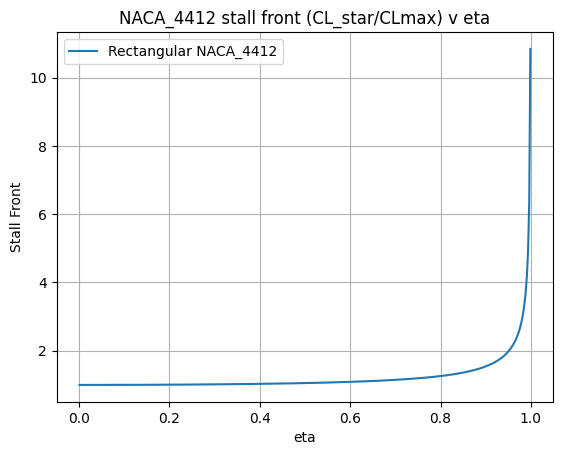

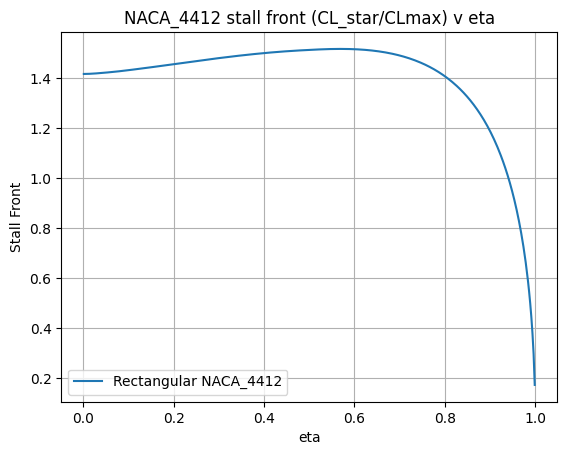

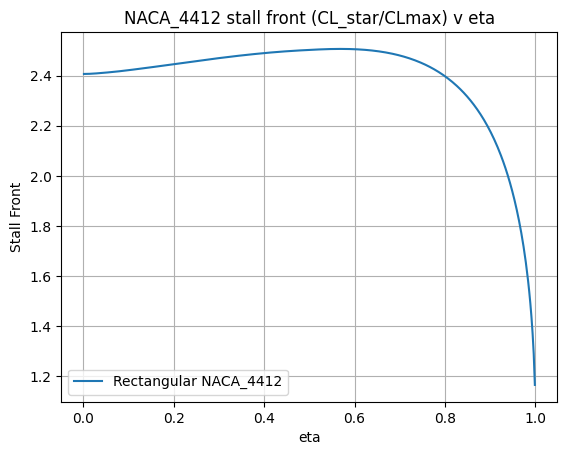

Design that meets req: [{'cb_cr': 1, 'ct_cr': 0.5, 'theta_b_deg': -2.0, 'theta_t_deg': -4, 'm_r_pct': 0, 'm_b_pct': 0.0, 'm_t_pct': 0.0}, array([0.8518262 , 0.85185126, 0.8519011 , 0.85197517, 0.85207266,
       0.85219254, 0.85233361, 0.85249449, 0.85267375, 0.85286986,
       0.85308133, 0.8533067 , 0.85354458, 0.85379374, 0.85405309,
       0.8543217 , 0.85459888, 0.85488408, 0.85517698, 0.85547743,
       0.85578545, 0.85610119, 0.85642488, 0.85675688, 0.85709754,
       0.85744723, 0.85780631, 0.85817507, 0.85855374, 0.85894245,
       0.85934122, 0.85974998, 0.86016856, 0.86059668, 0.86103399,
       0.86148007, 0.86193446, 0.8623967 , 0.86286631, 0.86334284,
       0.8638259 , 0.86431515, 0.86481033, 0.86531126, 0.86581785,
       0.86633009, 0.86684805, 0.86737187, 0.86790172, 0.86843783,
       0.86898044, 0.86952978, 0.87008607, 0.8706495 , 0.8712202 ,
       0.87179825, 0.87238366, 0.87297639, 0.87357632, 0.87418329,
       0.87479707, 0.87541743, 0.8760441 , 0.87667679, 0.8

In [34]:
check_profile_drag(inp, profile_drag)

## 5. Task 4: pitching moment

For a wing with a straight quarter-chord line, the pitching moment coefficient about the wing aerodynamic center, and the mean aerodynamic chord, are (handout Eq. 6)

$$C_{m,ac}=\frac{2}{S\bar c}\int_0^{b/2}c_{m,c/4}\,c^2\,dy,\qquad \bar c=\frac2S\int_0^{b/2}c^2\,dy .$$

Get $c_{m,c/4}(\eta)$ from `span_sections(design, section_properties)`. On the stations `ETA`, $dy = (b/2)\,d\eta$. Both integrals in Eq. (6) are over one half of the wing. Do both with `span_integral`.

Write `pitching_moment(design)`. It returns `(Cm_ac, cbar)`: $C_{m,ac}$ (a number) and $\bar c$ in m. The panel uses them for the tail load in cruise, $L_t\,l_t = q\,S\,\bar c\,C_{m,ac}$ ($L_t > 0$ up).

**Given tools for this function** (from `p2_lib.py`, already imported):
- `span_sections(design, section_properties)` for `cm_c4(eta)`.
- `design.chord(ETA)` (m), `design.b`, `design.S`.
- `span_integral(f)`: $\int_0^1 f\,d\eta$ for values `f` at the stations `ETA`.

In [15]:
def pitching_moment(design):
    """Wing pitching moment about its aerodynamic center, handout Eq. (6).

    Returns (Cm_ac, cbar): the moment coefficient, and the mean aerodynamic chord in m.

    Tools to use:
      span_sections(design, section_properties) -> cm_c4(eta).
      design.chord(ETA), design.b, design.S.
      span_integral(f) for both integrals over the half wing: dy = (b/2) d(eta).
    """
    _, cm_c4 = span_sections(design, section_properties)
    cm = np.asarray(cm_c4(ETA))
    c = design.chord(ETA)

    cbar = (2.0 / design.S) * (design.b / 2.0) * span_integral(c**2)
    Cm_ac = (2.0 / (design.S * cbar)) * (design.b / 2.0) * span_integral(cm * c**2)

    return Cm_ac, cbar

In [17]:
check_pitching_moment(inp, pitching_moment, section_properties)

Checks for pitching_moment(design):
  ok    a symmetric wing has C_m,ac = 0
  ok    rectangular wing with one section: C_m,ac equals the section c_m,c/4
  ok    rectangular wing: the mean aerodynamic chord equals the chord (m)
  ok    linear taper, taper ratio t = c_t/c_r = 0.5: c-bar = (2/3) c_r (1 + t + t^2)/(1 + t)
All 4 checks passed. (The checks find common mistakes. They do not prove that your function is correct.)


## 6. Task 5: root bending moment

The right wing puts this bending moment on the joiner at the root:

$$M_\text{root}=\int_0^{b/2}L'(y)\,y\,dy, \qquad L' = q\,c\,c_l .$$

Write `root_moment(span_load, b, L)`. `span_load` is $c\,c_l$ at each station in `ETA`. `L` is the total lift of the wing in N. It returns $M_\text{root}$ in N m. You do not need $q$: the right wing carries $L/2 = \int_0^{b/2} L'\,dy$, and this sets the scale of $L'$. So the result must not change if `span_load` is multiplied by a constant. Do both integrals with `span_integral`.

**Given tools for this function** (from `p2_lib.py`, already imported):
- `span_integral(f)`: $\int_0^1 f\,d\eta$ for values `f` at the stations `ETA`.
- `ETA`: the 400 span stations; $y = \eta\,b/2$, so $dy = (b/2)\,d\eta$.

In [25]:
def root_moment(span_load, b, L):
    """Root bending moment of the right wing, M_root = integral of L' y dy from 0 to b/2.

    span_load: c c_l at each station in ETA. Only its shape matters.
    b: span (m). L: total lift of the wing (N).
    Returns M_root in N m.

    Tools to use:
      span_integral(f) for both integrals: the moment of the load, and the load itself.
      ETA for eta; y = eta b/2, so dy = (b/2) d(eta).
    """
    f = np.asarray(span_load)

    # Normalize the load so the right wing carries L/2. With y = eta*b/2 and
    # dy = (b/2) d(eta), the factors of b/2 cancel in the ratio:
    #   M_root = (L/2) * (b/2) * int(f*eta) / int(f)
    return 0.5 * L * (b / 2.0) * span_integral(f * ETA) / span_integral(f)

In [19]:
check_root_moment(root_moment)

Checks for root_moment(span_load, b, L):
  ok    elliptic loading: M_root/(L b) = 0.106
  ok    uniform loading: M_root/(L b) = 0.125 (center of lift at b/4)
  ok    M_root is proportional to L and does not depend on the scale of span_load
All 3 checks passed. (The checks find common mistakes. They do not prove that your function is correct.)


## 7. The design panel

Move a slider and release it, or type a value next to it. The panel then shows:

- (a) the planform of the right half of the wing, with the flow from the top;
- (b) the camber and the twist along the span;
- (c) the section $c_l$ and $c_{l\max}$ along the span at the wing $C_{L\max}$. The dot is where the stall starts: the first station to reach its $c_{l\max}$.
- (d) the span load $c\,c_l/c_\text{avg}$ at $C_{L\max}$, with $c_\text{avg} = S/b$. The dashed line is the elliptic loading with the same $C_L$.
- (e) the stall front $C_L^*/C_{L\max}$. When the wing reaches $1.05\,C_{L\max}$, the stations under the dashed line at 1.05 have stalled. The dot is where the stall starts.
- Under the plots: $C_{L\max}$, where the stall starts, and the span stalled at $1.05\,C_{L\max}$.
- The cruise $e$, $C_{D_i}$, $C_{D_p}$ and wing $C_D$; $C_{m,ac}$ and the tail load.
- $M_\text{root}$ in level flight ($L = W$) at $C_{L\max}$.

The cruise values are at your P1 cruise speed and $C_L = W/(qS)$. The panel uses your seven functions. If one is not written yet, the panel shows which one, and shows everything that does not need it.

To start the panel at other values, change `[design]` in `p2_inputs.toml`, save it, and run the set-up cell and this cell again.

In [31]:
panel = show_panel(inp, section_properties, cl_max, loadings, stall_front, profile_drag,
                   pitching_moment, root_moment)

The cell below prints the design that the panel shows now, and its results, for your answer file. Run it again after you move a slider.

In [32]:
for name, value in panel.design.variables().items():
    print(f"{name:12s} = {value:.3f}")
print()
for name, value in panel.results.items():
    print(f"{name:12s} = {value:.5g}")
for message in sorted(set(panel.messages.values())):
    print(f"Not computed yet. {message}")

cb_cr        = 1.000
ct_cr        = 0.700
theta_b_deg  = -4.450
theta_t_deg  = -4.480
m_r_pct      = 4.200
m_b_pct      = 4.600
m_t_pct      = 4.600

CLmax        = 1.2321
eta_first    = 0.00125
stalled105   = 0.20833
e            = 0.99128
CDi          = 0.043048
CDp          = 0.012128
Cm_ac        = -0.1191
cbar         = 0.40248
L_tail       = -1.8512
M_root       = 3.3708
CD_wing      = 0.055175


## 8. Check your answer file

Open `p2_answers.toml`, replace every `nan` with your number, fill in `[team]`, and save. Then run the cell below. It checks the **format** and the design limits only, not whether your numbers are right. Fix what it lists and run it again until it says *format OK*.

In [38]:
from validate_p2_answers import main as validate

validate(["validate_p2_answers.py", "p2_answers.toml"]);

p2_answers.toml: format OK. (This does not check whether your numbers are correct.)
